# Sumativa 3 — Cierre y comunicación del proyecto

**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Proyecto:** *Online Shoppers Purchasing Intention*  
**Integrantes:** Verónica Durán Cisterna · Raúl Moya Arriagada · Daniela Rojas Vilches · Manuel Sánchez Cárcamo  
**Docente:** Dr. Jean Paul Maidana González

## Pregunta de investigación
> **¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?**

## Propósito
Integrar de forma trazable **S1 → S2 → S3**, comparar estrategias de manejo de faltantes, construir tres modelos de regresión logística, seleccionar y diagnosticar el mejor modelo, evaluar su estabilidad mediante bootstrap y analizar el impacto de la imputación.

El alcance es **asociativo y predictivo**, no causal.

## Retroalimentación incorporada (S2, Dr. Maidana — 23-oct)

| Indicación del docente | Dónde se aborda |
|---|---|
| Inducir faltantes controlados y comparar eliminación, imputación simple e imputación por regresión | Parte I (§4–§9) |
| Partición 70/30 estratificada por `Revenue` | §10 |
| Revisar el VIF **antes** de modelar: `BounceRates` y `ExitRates` superan 6, quedarse con una | §12 |
| Dejar `PageValues` fuera hasta confirmar cuándo está disponible | §11 y Parte VII |
| Tres logísticas: variables validadas, stepwise AIC y una reducida | §13–§15 |
| Ponderar clases (peso ≈ 3,2 para compras) y evaluar con matriz de confusión, recall y AUC | §13–§18 |
| Bootstrap de los coeficientes del mejor modelo para ver cuáles conservan su signo | Parte V |
| Simular el problema (escenario de decisión), no repetir el IC de S1 | Parte VIII |


## 1. Librerías y reproducibilidad

Se mantiene `RANDOM_STATE = 42`, utilizado en F2. El experimento MCAR usa exactamente las mismas variables y regla: 12 % de valores ocultados en `ProductRelated_Duration` y `ExitRates`.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, mean_absolute_error,
    mean_squared_error
)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
MISSING_RATE = 0.12
BOOTSTRAP_B = 2000
VIF_UMBRAL = 5
MC_SESIONES = 1000
MC_REPS = 10000
np.random.seed(RANDOM_STATE)

print("Semilla:", RANDOM_STATE)
print("MCAR:", f"{MISSING_RATE:.0%}")
print("Bootstrap:", BOOTSTRAP_B)
print("Umbral VIF:", VIF_UMBRAL)


Semilla: 42
MCAR: 12%
Bootstrap: 2000
Umbral VIF: 5


## 2. Carga del dataset original

S1 estableció que la base original contiene **12.330 sesiones, 18 variables y ningún valor faltante**. Por instrucción del curso para datasets completos, en F2 se introdujo faltante controlado MCAR. S3 debe trabajar con la misma versión reproducible.


In [2]:
candidatos = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv"),
    Path("../../data/raw/online_shoppers_intention.csv")
]
DATA_PATH = next((p for p in candidatos if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontró data/raw/online_shoppers_intention.csv")

df_original = pd.read_csv(DATA_PATH)
print("Archivo:", DATA_PATH.resolve())
print("Dimensiones:", df_original.shape)
print("Faltantes originales:", int(df_original.isna().sum().sum()))
display(df_original.head())

assert df_original.shape == (12330, 18)
assert df_original.isna().sum().sum() == 0


Archivo: C:\Users\darve\proyecto-grupo2-mcdi501\data\raw\online_shoppers_intention.csv
Dimensiones: (12330, 18)
Faltantes originales: 0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Trazabilidad S1 → S2 → S3

### S1
- `Revenue` está desbalanceada: aproximadamente 15,47 % de sesiones terminan en compra.
- `PageValues` presentó una asociación especialmente fuerte con `Revenue`.
- `VisitorType` presentó asociación significativa, aunque de magnitud pequeña.
- Se observaron distribuciones asimétricas y valores extremos.
- Correlaciones altas: `BounceRates`–`ExitRates`, `ProductRelated`–`ProductRelated_Duration`, entre otras.

### S2
El remuestreo confirmó estabilidad en:
- `BounceRates`–`ExitRates`: r ≈ 0,913.
- `ProductRelated`–`ProductRelated_Duration`: r ≈ 0,861.
- `Informational`–`Informational_Duration`: r ≈ 0,619.
- `Administrative`–`Administrative_Duration`: r ≈ 0,602.

El jackknife mostró que los valores extremos afectan globalmente algunos estimadores, pero ninguna observación individual domina la media. Por ello **no se eliminan outliers automáticamente**.

### F2
Se introdujo 12 % MCAR en `ProductRelated_Duration` y `ExitRates`, se aplicó mediana y se obtuvo un primer modelo logístico. S3 amplía ese flujo.


## 4. Reproducción exacta del escenario MCAR de F2

El mecanismo es **MCAR** porque cada observación tiene igual probabilidad de ser ocultada y la selección no depende de su valor, de otros predictores ni de `Revenue`. La variable objetivo nunca se elimina ni se usa para generar la máscara.


In [3]:
VARIABLES_MCAR = ["ProductRelated_Duration", "ExitRates"]

df_mcar = df_original.copy()
valores_verdaderos = df_original[VARIABLES_MCAR].copy()
indices_mcar = {}

for i, variable in enumerate(VARIABLES_MCAR):
    rng = np.random.default_rng(RANDOM_STATE + i)
    n_missing = round(MISSING_RATE * len(df_mcar))
    idx = rng.choice(df_mcar.index.to_numpy(), size=n_missing, replace=False)
    indices_mcar[variable] = idx
    df_mcar.loc[idx, variable] = np.nan

resumen = pd.DataFrame({
    "Variable": VARIABLES_MCAR,
    "n_faltantes": [df_mcar[v].isna().sum() for v in VARIABLES_MCAR],
    "porcentaje": [100*df_mcar[v].isna().mean() for v in VARIABLES_MCAR]
})
display(resumen.round(2))
assert df_mcar["Revenue"].isna().sum() == 0


,Variable,n_faltantes,porcentaje
0,ProductRelated_Duration,1480,12.0
1,ExitRates,1480,12.0


# PARTE I — Manejo inteligente de datos faltantes

## 5. Tres estrategias

Se construirán tres datasets:

1. **Eliminación completa:** se eliminan filas con faltantes en las variables MCAR.
2. **Imputación simple:** mediana.
3. **Imputación mediante regresión lineal múltiple:** cada variable faltante se estima usando predictores seleccionados desde S1/S2.

Para evitar fuga de información durante la evaluación predictiva, más adelante cada estrategia se aplicará respetando la separación entrenamiento/prueba. En esta primera comparación descriptiva se construyen las versiones completas para estudiar tamaño muestral, distribución y correlaciones.


In [4]:
# 1) Eliminación
df_delete = df_mcar.dropna(subset=VARIABLES_MCAR).copy()

# 2) Mediana (comparación descriptiva global; el modelamiento posterior será train-only)
df_median = df_mcar.copy()
for v in VARIABLES_MCAR:
    df_median[v] = df_median[v].fillna(df_median[v].median())

print("Original:", len(df_original))
print("Eliminación:", len(df_delete))
print("Mediana:", len(df_median))


Original: 12330
Eliminación: 9558
Mediana: 12330


## 6. Imputación por regresión múltiple

Predictores elegidos según relaciones observadas y validadas, **excluyendo `PageValues`**: si no se puede confirmar que está disponible al momento de predecir, tampoco debe usarse para reconstruir otras variables (sería una vía indirecta de fuga de información).

### `ProductRelated_Duration`
- `ProductRelated`: correlación fuerte y estable en S2 (r ≈ 0,861).
- `Administrative_Duration`
- `Informational_Duration`
- `BounceRates`

### `ExitRates`
- `BounceRates`: correlación muy fuerte y estable en S2 (r ≈ 0,913).
- `ProductRelated_Duration`
- `ProductRelated`
- `SpecialDay`

`BounceRates` se usa para imputar aunque luego se excluya del modelo logístico por VIF: la multicolinealidad perjudica la interpretación de coeficientes de un modelo, pero es precisamente lo que hace buena a una regresión de imputación.

`Revenue` **no se utiliza para imputar**, evitando usar el objetivo como predictor del proceso de imputación.

In [5]:
REG_PREDICTORS = {
    "ProductRelated_Duration": [
        "ProductRelated", "Administrative_Duration",
        "Informational_Duration", "BounceRates"
    ],
    "ExitRates": [
        "BounceRates", "ProductRelated_Duration",
        "ProductRelated", "SpecialDay"
    ]
}

def regression_impute_fit_transform(train_df, other_df=None):
    """Ajusta las regresiones SOLO con train_df y transforma train y, opcionalmente, other_df."""
    train_imp = train_df.copy()
    other_imp = None if other_df is None else other_df.copy()
    fitted = {}

    # Primero ProductRelated_Duration; luego ExitRates puede usarla ya imputada.
    for target in VARIABLES_MCAR:
        predictors = REG_PREDICTORS[target]
        complete = train_imp[target].notna() & train_imp[predictors].notna().all(axis=1)

        X_fit = sm.add_constant(train_imp.loc[complete, predictors].astype(float), has_constant="add")
        y_fit = train_imp.loc[complete, target].astype(float)
        reg = sm.OLS(y_fit, X_fit).fit()
        fitted[target] = reg

        miss_train = train_imp[target].isna()
        if miss_train.any():
            Xmiss = sm.add_constant(train_imp.loc[miss_train, predictors].astype(float), has_constant="add")
            pred = reg.predict(Xmiss)
            # Las variables analizadas no admiten valores negativos.
            train_imp.loc[miss_train, target] = np.maximum(pred, 0)

        if other_imp is not None:
            miss_other = other_imp[target].isna()
            if miss_other.any():
                # Si ExitRates usa ProductRelated_Duration, ésta ya fue imputada en la iteración anterior.
                Xmiss = sm.add_constant(other_imp.loc[miss_other, predictors].astype(float), has_constant="add")
                pred = reg.predict(Xmiss)
                other_imp.loc[miss_other, target] = np.maximum(pred, 0)

    return train_imp, other_imp, fitted

df_regression, _, modelos_imputacion_global = regression_impute_fit_transform(df_mcar)

print("Faltantes tras imputación por regresión:",
      int(df_regression[VARIABLES_MCAR].isna().sum().sum()))
for target, reg in modelos_imputacion_global.items():
    print(f"\n{target}: R²={reg.rsquared:.4f}, R² ajustado={reg.rsquared_adj:.4f}")


Faltantes tras imputación por regresión: 0

ProductRelated_Duration: R²=0.7605, R² ajustado=0.7604

ExitRates: R²=0.8511, R² ajustado=0.8510


## 7. Diagnóstico de los modelos de imputación

Para cada regresión de imputación se revisan:
- R² y R² ajustado;
- normalidad aproximada de residuos mediante Q-Q plot;
- homocedasticidad visual residuos vs. ajustados;
- VIF de predictores.

Estos diagnósticos se utilizan como evidencia de calidad de la imputación, reconociendo que el objetivo principal es estimar valores faltantes y no realizar inferencia causal.



MODELO DE IMPUTACIÓN: ProductRelated_Duration
                               OLS Regression Results                              
Dep. Variable:     ProductRelated_Duration   R-squared:                       0.761
Model:                                 OLS   Adj. R-squared:                  0.760
Method:                      Least Squares   F-statistic:                     8609.
Date:                     Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                             23:31:43   Log-Likelihood:                -89744.
No. Observations:                    10850   AIC:                         1.795e+05
Df Residuals:                        10845   BIC:                         1.795e+05
Df Model:                                4                                         
Covariance Type:                 nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------

,Variable,VIF
0,ProductRelated,1.190
1,Administrative_Duration,1.138
2,Informational_Duration,1.128
3,BounceRates,1.052


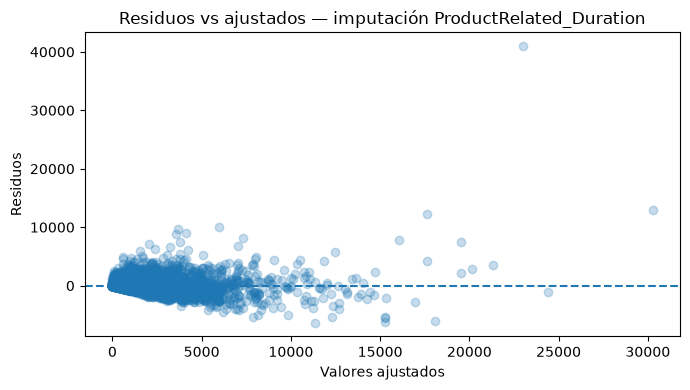

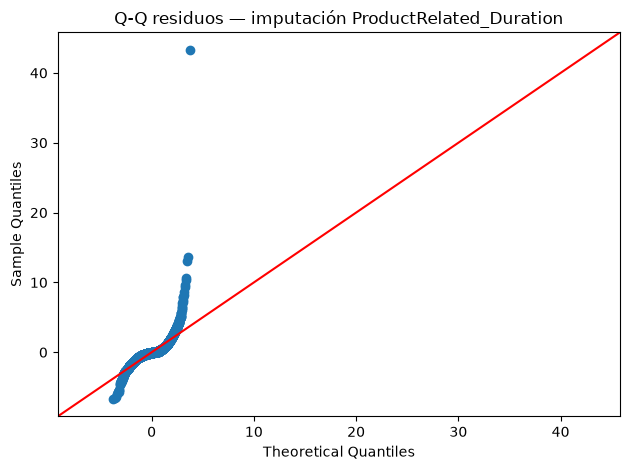


MODELO DE IMPUTACIÓN: ExitRates
                            OLS Regression Results                            
Dep. Variable:              ExitRates   R-squared:                       0.851
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                 1.549e+04
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:31:44   Log-Likelihood:                 27636.
No. Observations:               10850   AIC:                        -5.526e+04
Df Residuals:                   10845   BIC:                        -5.523e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------

,Variable,VIF
0,BounceRates,1.050
1,ProductRelated_Duration,3.761
2,ProductRelated,3.794
3,SpecialDay,1.007


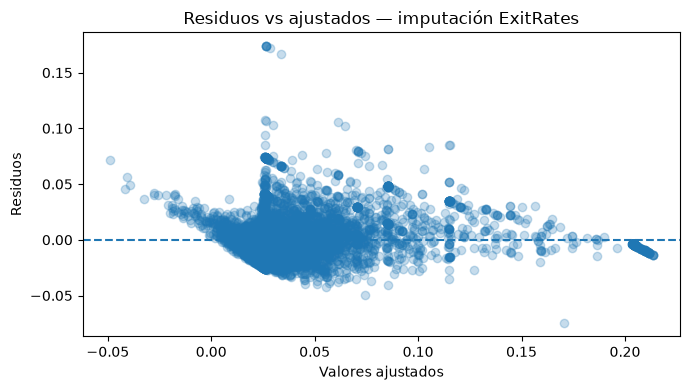

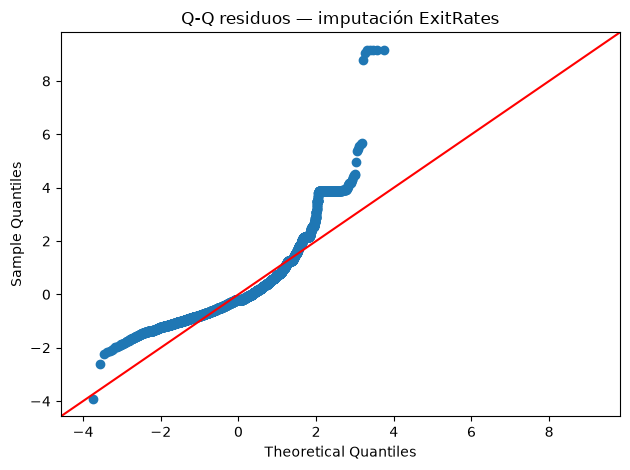

In [6]:
for target, reg in modelos_imputacion_global.items():
    print("\n", "="*70)
    print("MODELO DE IMPUTACIÓN:", target)
    print(reg.summary())

    pred = REG_PREDICTORS[target]
    Xc = df_mcar.loc[df_mcar[target].notna(), pred].dropna().astype(float)
    vif = pd.DataFrame({
        "Variable": Xc.columns,
        "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]
    })
    display(vif.round(3))

    plt.figure(figsize=(7,4))
    plt.scatter(reg.fittedvalues, reg.resid, alpha=.25)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Valores ajustados")
    plt.ylabel("Residuos")
    plt.title(f"Residuos vs ajustados — imputación {target}")
    plt.tight_layout()
    plt.show()

    sm.qqplot(reg.resid, line="45", fit=True)
    plt.title(f"Q-Q residuos — imputación {target}")
    plt.tight_layout()
    plt.show()


## 8. Error real de imputación: mediana vs. regresión

Como los faltantes fueron generados artificialmente, conocemos el valor verdadero ocultado. Esto permite comparar objetivamente **MAE y RMSE**.


In [7]:
errores_imp = []

for v in VARIABLES_MCAR:
    idx = indices_mcar[v]
    real = valores_verdaderos.loc[idx, v]

    pred_med = df_median.loc[idx, v]
    pred_reg = df_regression.loc[idx, v]

    for metodo, pred in [("Mediana", pred_med), ("Regresión", pred_reg)]:
        errores_imp.append({
            "Variable": v,
            "Método": metodo,
            "MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred))
        })

tabla_error = pd.DataFrame(errores_imp)
display(tabla_error.round(4))


,Variable,Método,MAE,RMSE
0,ProductRelated_Duration,Mediana,982.0408,1860.8516
1,ProductRelated_Duration,Regresión,469.9627,832.4377
2,ExitRates,Mediana,0.0271,0.0471
3,ExitRates,Regresión,0.0136,0.0195


## 9. Comparación de tamaño, distribución y preservación de correlaciones

La pauta exige comparar las tres estrategias en tamaño muestral, distribución y preservación de las correlaciones de S1. Se usan como referencia los pares más relevantes validados en S2.


In [8]:
datasets_imp = {
    "Original": df_original,
    "Eliminación": df_delete,
    "Mediana": df_median,
    "Regresión": df_regression
}

filas = []
for nombre, d in datasets_imp.items():
    for v in VARIABLES_MCAR:
        filas.append({
            "Dataset": nombre,
            "Variable": v,
            "n": d[v].notna().sum(),
            "Media": d[v].mean(),
            "Mediana": d[v].median(),
            "DE": d[v].std(),
            "Q1": d[v].quantile(.25),
            "Q3": d[v].quantile(.75)
        })
display(pd.DataFrame(filas).round(4))

corr_rows = []
for nombre, d in datasets_imp.items():
    corr_rows.append({
        "Dataset": nombre,
        "r_BounceRates_ExitRates": d[["BounceRates","ExitRates"]].corr().iloc[0,1],
        "r_ProductRelated_Duration": d[["ProductRelated","ProductRelated_Duration"]].corr().iloc[0,1]
    })
tabla_corr = pd.DataFrame(corr_rows)
display(tabla_corr.round(4))


,Dataset,Variable,n,Media,Mediana,DE,Q1,Q3
0,Original,ProductRelated_Duration,12330,1194.7462,598.9369,1913.6693,184.1375,1464.1572
1,Original,ExitRates,12330,0.0431,0.0252,0.0486,0.0143,0.0500
2,Eliminación,ProductRelated_Duration,9558,1195.4977,592.0750,1955.4739,183.0238,1462.6068
3,Eliminación,ExitRates,9558,0.0435,0.0254,0.0491,0.0143,0.0500
4,Mediana,ProductRelated_Duration,12330,1122.8589,597.1667,1824.0634,226.0641,1287.9319
5,Mediana,ExitRates,12330,0.0413,0.0254,0.0464,0.0155,0.0439
6,Regresión,ProductRelated_Duration,12330,1195.3755,602.2350,1900.2804,192.4625,1460.4890
7,Regresión,ExitRates,12330,0.0430,0.0259,0.0481,0.0154,0.0481


,Dataset,r_BounceRates_ExitRates,r_ProductRelated_Duration
0,Original,0.9130,0.8609
1,Eliminación,0.9150,0.8566
2,Mediana,0.8673,0.8015
3,Regresión,0.9220,0.8706


### Criterio para escoger estrategia

Se priorizará la estrategia que:
1. preserve mejor las relaciones observadas en S1/S2;
2. presente menor MAE/RMSE cuando corresponda;
3. evite pérdida innecesaria de muestra;
4. mantenga coherencia estadística y sustantiva.

El código siguiente selecciona automáticamente entre **mediana** y **regresión** usando el RMSE promedio. La eliminación se conserva como estrategia comparativa, pero no se prioriza si supone pérdida de observaciones.


In [9]:
rmse_prom = tabla_error.groupby("Método")["RMSE"].mean()
METODO_PRINCIPAL = rmse_prom.idxmin()
print("RMSE promedio:")
display(rmse_prom.to_frame())
print("Estrategia principal sugerida:", METODO_PRINCIPAL)


RMSE promedio:


,RMSE
Método,
Mediana,930.449346
Regresión,416.228584


Estrategia principal sugerida: Regresión


# PARTE II — Clasificación mediante regresión logística

## 10. Partición 70/30

Para mantener comparabilidad entre modelos, se utiliza una única partición estratificada de índices. Las imputaciones de mediana/regresión para el modelamiento se ajustan **solo con entrenamiento**, evitando fuga de información.


In [10]:
indices = df_mcar.index
train_idx, test_idx = train_test_split(
    indices,
    test_size=.30,
    random_state=RANDOM_STATE,
    stratify=df_mcar["Revenue"].astype(int)
)

train_raw = df_mcar.loc[train_idx].copy()
test_raw = df_mcar.loc[test_idx].copy()

# Mediana train-only
train_med = train_raw.copy()
test_med = test_raw.copy()
for v in VARIABLES_MCAR:
    med = train_med[v].median()
    train_med[v] = train_med[v].fillna(med)
    test_med[v] = test_med[v].fillna(med)

# Regresión train-only
train_reg, test_reg, modelos_imp_train = regression_impute_fit_transform(train_raw, test_raw)

# Eliminación
train_del = train_raw.dropna(subset=VARIABLES_MCAR).copy()
test_del = test_raw.dropna(subset=VARIABLES_MCAR).copy()

if METODO_PRINCIPAL == "Regresión":
    train_main, test_main = train_reg, test_reg
else:
    train_main, test_main = train_med, test_med

print("Método principal:", METODO_PRINCIPAL)
print("Train/Test principal:", len(train_main), len(test_main))
print("Eliminación Train/Test:", len(train_del), len(test_del))


Método principal: Regresión
Train/Test principal: 8631 3699
Eliminación Train/Test: 6695 2863


## 11. Outliers y disponibilidad de `PageValues`

**Outliers.** S1/S2 identificaron asimetría y valores extremos, pero el jackknife de S2 mostró que ninguna observación individual domina los estimadores. Por ello **se conservan los outliers**, acompañados de estandarización de las variables numéricas.

**`PageValues`.** Es la variable más asociada a `Revenue` (S1, S2), pero el sitio la calcula a partir del valor de las páginas visitadas *antes de completar una transacción*; no está claro que el valor esté disponible cuando la sesión aún está en curso. Siguiendo la indicación del docente, **se deja fuera de los tres modelos** y solo se evalúa en la Parte VII como escenario condicionado a confirmar su disponibilidad.

## 12. Preparación de predictores y filtro VIF previo

Se construye la matriz de candidatos (sin `Revenue` ni `PageValues`), se codifica `VisitorType` con `get_dummies(drop_first=True)` y se estandarizan las numéricas con parámetros aprendidos solo en entrenamiento.

**Antes de ajustar cualquier modelo** se calcula el VIF de todas las candidatas. Regla: mientras el VIF máximo supere 5, se identifica la variable con mayor VIF y su par más correlacionado, y se conserva la que fue validada en S1/S2.

In [11]:
CANDIDATOS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay",
    "VisitorType", "Weekend"
]

NUM_SCALE = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "SpecialDay", "PageValues"
]

def preparar_matrices(train_df, test_df, columnas=CANDIDATOS + ["PageValues"]):
    tr = train_df[columnas].copy()
    te = test_df[columnas].copy()

    tr["Weekend"] = tr["Weekend"].astype(int)
    te["Weekend"] = te["Weekend"].astype(int)

    combinado = pd.concat([tr.assign(_set="train"), te.assign(_set="test")])
    combinado = pd.get_dummies(combinado, columns=["VisitorType"], drop_first=True, dtype=float)

    tr2 = combinado[combinado["_set"]=="train"].drop(columns="_set")
    te2 = combinado[combinado["_set"]=="test"].drop(columns="_set")

    escalar = [c for c in NUM_SCALE if c in tr2.columns]
    scaler = StandardScaler()
    tr2[escalar] = scaler.fit_transform(tr2[escalar])
    te2[escalar] = scaler.transform(te2[escalar])

    return tr2.astype(float), te2.astype(float), scaler

# PageValues se prepara (estandarizada) pero NO entra a la lista de candidatas.
Xtr_all, Xte_all, scaler_main = preparar_matrices(train_main, test_main)
ytr = train_main["Revenue"].astype(int)
yte = test_main["Revenue"].astype(int)

CAND_COLS = [c for c in Xtr_all.columns if c != "PageValues"]
print("Candidatas (sin PageValues):", CAND_COLS)

Candidatas (sin PageValues): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'Weekend', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


In [12]:
def tabla_vif(X, cols):
    Xc = sm.add_constant(X[cols], has_constant="add").values
    return pd.DataFrame({
        "Variable": cols,
        "VIF": [variance_inflation_factor(Xc, i + 1) for i in range(len(cols))]
    }).sort_values("VIF", ascending=False).reset_index(drop=True)

# Variables respaldadas por S1/S2 (se conservan cuando forman parte de un par colineal)
VALIDADAS_S1S2 = ["ExitRates", "ProductRelated_Duration", "VisitorType_Returning_Visitor",
                  "VisitorType_Other", "Weekend"]

vif_inicial = tabla_vif(Xtr_all, CAND_COLS)
print("VIF inicial de las candidatas (entrenamiento):")
display(vif_inicial.round(2))

cols_vif = list(CAND_COLS)
excluidas_vif = []
while True:
    t = tabla_vif(Xtr_all, cols_vif)
    v_max, vif_max = t.loc[0, "Variable"], t.loc[0, "VIF"]
    if vif_max <= VIF_UMBRAL:
        break
    corr = Xtr_all[cols_vif].corr()[v_max].drop(v_max).abs()
    par = corr.idxmax()
    quitar = par if v_max in VALIDADAS_S1S2 else v_max
    excluidas_vif.append({"Excluida": quitar, "Par": v_max if quitar == par else par,
                          "VIF": t.set_index("Variable").loc[quitar, "VIF"],
                          "r_par": corr.max()})
    cols_vif.remove(quitar)

display(pd.DataFrame(excluidas_vif).round(3))
vif_final = tabla_vif(Xtr_all, cols_vif)
print("VIF tras el filtro:")
display(vif_final.round(2))

CAND_COLS = cols_vif
print("Candidatas finales:", CAND_COLS)

VIF inicial de las candidatas (entrenamiento):


,Variable,VIF
0,ExitRates,7.54
1,BounceRates,6.83
2,ProductRelated,4.52
3,ProductRelated_Duration,4.48
4,Administrative,1.91
5,Informational,1.88
6,Informational_Duration,1.76
7,Administrative_Duration,1.70
8,VisitorType_Returning_Visitor,1.14
9,VisitorType_Other,1.06


,Excluida,Par,VIF,r_par
0,BounceRates,ExitRates,6.834,0.919


VIF tras el filtro:


,Variable,VIF
0,ProductRelated_Duration,4.47
1,ProductRelated,4.46
2,Administrative,1.90
3,Informational,1.88
4,Informational_Duration,1.76
5,Administrative_Duration,1.70
6,ExitRates,1.21
7,VisitorType_Returning_Visitor,1.13
8,VisitorType_Other,1.06
9,SpecialDay,1.02


Candidatas finales: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay', 'Weekend', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


## 13. Ponderación de clases y Modelo 1 — variables validadas en S1/S2

Solo el 15,47 % de las sesiones termina en compra. Siguiendo la indicación del docente, **todos los modelos se ajustan con ponderación de clases** (`balanced`): peso $n/(2n_1) \approx 3{,}2$ para las compras y $n/(2n_0) \approx 0{,}6$ para las no compras. Los pesos suman $n$, de modo que la escala del log-verosimilitud se mantiene comparable.

Los modelos se ajustan como GLM binomial con `freq_weights`. Con pesos, los errores estándar del modelo son aproximados; por eso la Parte V contrasta los IC tradicionales con IC bootstrap.

**M1** usa las variables que S1/S2 validaron y que sobrevivieron al filtro VIF: `ExitRates`, `ProductRelated_Duration`, `VisitorType` y `Weekend`.

In [13]:
def pesos_clase(y):
    y = np.asarray(y)
    n, n1 = len(y), y.sum()
    return np.where(y == 1, n / (2 * n1), n / (2 * (n - n1)))

w_tr = pesos_clase(ytr)
print(f"Peso compras: {w_tr[ytr.values==1][0]:.3f} | peso no compras: {w_tr[ytr.values==0][0]:.3f}")

def fit_logit(X, y, vars_, ponderado=True):
    Xs = sm.add_constant(X[vars_], has_constant="add")
    w = pesos_clase(y) if ponderado else None
    return sm.GLM(y, Xs, family=sm.families.Binomial(), freq_weights=w).fit()

def predecir(mod, X, vars_):
    return mod.predict(sm.add_constant(X[vars_], has_constant="add"))

M1_VARS = [v for v in ["ExitRates", "ProductRelated_Duration", "VisitorType_Other",
                       "VisitorType_Returning_Visitor", "Weekend"] if v in CAND_COLS]
m1 = fit_logit(Xtr_all, ytr, M1_VARS)
print(m1.summary())

Peso compras: 3.230 | peso no compras: 0.592
                 Generalized Linear Model Regression Results                  
Dep. Variable:                Revenue   No. Observations:                 8631
Model:                            GLM   Df Residuals:                     8625
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -5180.3
Date:                Mon, 26 Oct 2026   Deviance:                       10361.
Time:                        23:31:48   Pearson chi2:                 1.75e+04
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1696
Covariance Type:            nonrobust                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------

## 14. Modelo 2 — selección stepwise por AIC

Procedimiento stepwise bidireccional sobre las candidatas que pasaron el filtro VIF. En cada iteración se evalúa agregar o retirar una variable y se conserva el cambio que más reduzca el AIC.

In [14]:
def criterio(X, y, variables, tipo):
    try:
        model = fit_logit(X, y, variables)
        return (model.aic if tipo == "aic" else model.bic_llf), model
    except Exception:
        return np.inf, None

def stepwise_aic(X, y, candidates):
    selected = []
    current, current_model = criterio(X, y, selected, "aic")
    while True:
        options = [("add", v, *criterio(X, y, selected + [v], "aic"))
                   for v in candidates if v not in selected]
        options += [("drop", v, *criterio(X, y, [x for x in selected if x != v], "aic"))
                    for v in selected]
        if not options:
            break
        action, var, best, best_model = min(options, key=lambda x: x[2])
        if best + 1e-8 >= current:
            break
        selected.append(var) if action == "add" else selected.remove(var)
        current, current_model = best, best_model
        print(action, var, "AIC =", round(current, 3))
    return selected, current_model

M2_VARS, m2 = stepwise_aic(Xtr_all, ytr, CAND_COLS)
print("\nVariables M2:", M2_VARS)
print("AIC M2:", round(m2.aic, 2))

add ExitRates AIC = 10504.159
add ProductRelated_Duration AIC = 10416.91
add SpecialDay AIC = 10335.432
add VisitorType_Returning_Visitor AIC = 10299.087
add Administrative AIC = 10287.651
add Weekend AIC = 10285.571
add Informational AIC = 10283.702

Variables M2: ['ExitRates', 'ProductRelated_Duration', 'SpecialDay', 'VisitorType_Returning_Visitor', 'Administrative', 'Weekend', 'Informational']
AIC M2: 10283.7


## 15. Modelo 3 — modelo reducido (backward por BIC)

El tercer modelo es la versión **reducida** que pide el docente. Parte del conjunto completo de candidatas y elimina en cada paso la variable cuya exclusión más reduce el BIC, criterio que penaliza la complejidad con más fuerza que el AIC.

In [15]:
def backward_bic(X, y, candidates):
    selected = list(candidates)
    current, current_model = criterio(X, y, selected, "bic")
    while len(selected) > 1:
        options = [(v, *criterio(X, y, [x for x in selected if x != v], "bic")) for v in selected]
        var, best, best_model = min(options, key=lambda x: x[1])
        if best + 1e-8 >= current:
            break
        selected.remove(var)
        current, current_model = best, best_model
        print("drop", var, "BIC =", round(current, 3))
    return selected, current_model

M3_VARS, m3 = backward_bic(Xtr_all, ytr, CAND_COLS)
print("\nVariables M3:", M3_VARS)
print("BIC M3:", round(m3.bic_llf, 2))

drop VisitorType_Other BIC = 10365.868
drop ProductRelated BIC = 10357.224
drop Administrative_Duration BIC = 10348.483
drop Informational_Duration BIC = 10340.207
drop Informational BIC = 10335.013
drop Weekend BIC = 10330.03

Variables M3: ['Administrative', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay', 'VisitorType_Returning_Visitor']
BIC M3: 10330.03


## 16. Coeficientes y odds ratios de los tres modelos

In [16]:
modelos = {"M1_S1S2": (m1, M1_VARS), "M2_Stepwise_AIC": (m2, M2_VARS), "M3_Reducido_BIC": (m3, M3_VARS)}

for nombre, (mod, vars_) in modelos.items():
    ci = mod.conf_int()
    tab = pd.DataFrame({
        "Coef": mod.params,
        "OR": np.exp(mod.params),
        "IC95_OR_inf": np.exp(ci[0]),
        "IC95_OR_sup": np.exp(ci[1]),
        "p": mod.pvalues
    })
    print("\n", nombre, "| Variables:", vars_)
    display(tab.round(4))


 M1_S1S2 | Variables: ['ExitRates', 'ProductRelated_Duration', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Weekend']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-0.2065,0.8134,0.7100,0.9319,0.0029
ExitRates,-1.5538,0.2114,0.1850,0.2417,0.0000
ProductRelated_Duration,0.2851,1.3299,1.2582,1.4056,0.0000
VisitorType_Other,-0.0033,0.9967,0.5682,1.7483,0.9908
VisitorType_Returning_Visitor,-0.4282,0.6517,0.5739,0.7400,0.0000
Weekend,0.1221,1.1299,1.0152,1.2575,0.0253



 M2_Stepwise_AIC | Variables: ['ExitRates', 'ProductRelated_Duration', 'SpecialDay', 'VisitorType_Returning_Visitor', 'Administrative', 'Weekend', 'Informational']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-0.2263,0.7975,0.6974,0.9118,0.0009
ExitRates,-1.4649,0.2311,0.2021,0.2643,0.0000
ProductRelated_Duration,0.2308,1.2596,1.1866,1.3372,0.0000
SpecialDay,-0.2664,0.7661,0.7176,0.8180,0.0000
VisitorType_Returning_Visitor,-0.4123,0.6621,0.5839,0.7508,0.0000
Administrative,0.0772,1.0802,1.0278,1.1353,0.0024
Weekend,0.1098,1.1161,1.0021,1.2431,0.0457
Informational,0.0484,1.0496,0.9999,1.1017,0.0505



 M3_Reducido_BIC | Variables: ['Administrative', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay', 'VisitorType_Returning_Visitor']


,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
const,-0.2064,0.8135,0.7128,0.9283,0.0022
Administrative,0.0896,1.0937,1.0423,1.1477,0.0003
ProductRelated_Duration,0.2432,1.2753,1.2034,1.3515,0.0000
ExitRates,-1.4694,0.2301,0.2012,0.2631,0.0000
SpecialDay,-0.2697,0.7636,0.7151,0.8155,0.0000
VisitorType_Returning_Visitor,-0.4050,0.6670,0.5883,0.7562,0.0000


## 17. Evaluación train/test: matriz de confusión, recall y AUC

Se reportan matrices de confusión y métricas en **entrenamiento y prueba**. Con ponderación, el umbral 0,5 equivale a clasificar como compra cuando la probabilidad ajustada supera la prevalencia aproximada, lo que favorece el recall de la clase minoritaria.

In [17]:
def evaluar_modelo(mod, Xtr, ytr, Xte, yte, vars_, nombre, threshold=.5):
    rows = []
    cms = {}
    for split, X, y in [("Train", Xtr, ytr), ("Test", Xte, yte)]:
        p = predecir(mod, X, vars_)
        pred = (p >= threshold).astype(int)
        rows.append({
            "Modelo": nombre, "Split": split,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, p)
        })
        cms[split] = confusion_matrix(y, pred)
    return rows, cms

metric_rows = []
matrices = {}
for nombre, (mod, vars_) in modelos.items():
    rows, cms = evaluar_modelo(mod, Xtr_all, ytr, Xte_all, yte, vars_, nombre)
    metric_rows += rows
    matrices[nombre] = cms

metricas_modelos = pd.DataFrame(metric_rows)
display(metricas_modelos.round(4))

for nombre, cms in matrices.items():
    print("\n", nombre)
    for split in ["Train", "Test"]:
        display(pd.DataFrame(cms[split],
                             index=["Real: no compra", "Real: compra"],
                             columns=["Pred: no compra", "Pred: compra"]).rename_axis(split))

,Modelo,Split,Accuracy,Precision,Recall,F1,AUC
0,M1_S1S2,Train,0.6031,0.2469,0.7627,0.3730,0.7291
1,M1_S1S2,Test,0.6007,0.2416,0.7395,0.3642,0.7087
2,M2_Stepwise_AIC,Train,0.6056,0.2494,0.7702,0.3768,0.7339
3,M2_Stepwise_AIC,Test,0.5975,0.2393,0.7360,0.3612,0.7089
4,M3_Reducido_BIC,Train,0.6042,0.2481,0.7665,0.3748,0.7328
5,M3_Reducido_BIC,Test,0.5980,0.2396,0.7360,0.3615,0.7076



 M1_S1S2


,Pred: no compra,Pred: compra
Train,,
Real: no compra,4186,3109
Real: compra,317,1019


,Pred: no compra,Pred: compra
Test,,
Real: no compra,1799,1328
Real: compra,149,423



 M2_Stepwise_AIC


,Pred: no compra,Pred: compra
Train,,
Real: no compra,4198,3097
Real: compra,307,1029


,Pred: no compra,Pred: compra
Test,,
Real: no compra,1789,1338
Real: compra,151,421



 M3_Reducido_BIC


,Pred: no compra,Pred: compra
Train,,
Real: no compra,4191,3104
Real: compra,312,1024


,Pred: no compra,Pred: compra
Test,,
Real: no compra,1791,1336
Real: compra,151,421


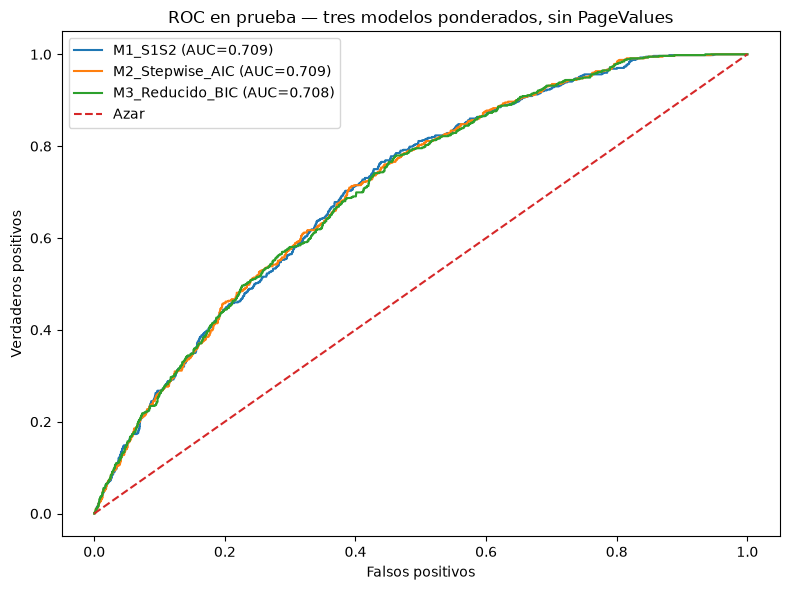

In [18]:
plt.figure(figsize=(8,6))
for nombre, (mod, vars_) in modelos.items():
    p = predecir(mod, Xte_all, vars_)
    fpr, tpr, _ = roc_curve(yte, p)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(yte, p):.3f})")
plt.plot([0,1], [0,1], "--", label="Azar")
plt.xlabel("Falsos positivos")
plt.ylabel("Verdaderos positivos")
plt.title("ROC en prueba — tres modelos ponderados, sin PageValues")
plt.legend()
plt.tight_layout()
plt.show()

## 18. Selección del mejor modelo (validación cruzada en entrenamiento)

Para no usar el conjunto de prueba en la elección, el modelo se selecciona con **validación cruzada estratificada de 5 particiones dentro de entrenamiento**. Regla explícita:

1. calcular el AUC medio de validación cruzada de cada modelo;
2. considerar equivalentes los modelos a ≤ 0,005 del mejor AUC medio;
3. entre ellos, elegir el más parsimonioso; desempate por recall medio.

El conjunto de prueba queda reservado para la evaluación final reportada en §17.

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for nombre, (_, vars_) in modelos.items():
    for k, (i_tr, i_va) in enumerate(skf.split(Xtr_all, ytr)):
        Xa, Xv = Xtr_all.iloc[i_tr], Xtr_all.iloc[i_va]
        ya, yv = ytr.iloc[i_tr], ytr.iloc[i_va]
        mod_k = fit_logit(Xa, ya, vars_)
        p = predecir(mod_k, Xv, vars_)
        cv_rows.append({"Modelo": nombre, "fold": k,
                        "AUC": roc_auc_score(yv, p),
                        "Recall": recall_score(yv, (p >= .5).astype(int))})

cv_res = (pd.DataFrame(cv_rows).groupby("Modelo")
          .agg(AUC_cv=("AUC", "mean"), AUC_cv_de=("AUC", "std"), Recall_cv=("Recall", "mean")))
cv_res["n_variables"] = [len(modelos[m][1]) for m in cv_res.index]
cv_res["Delta_AUC_mejor"] = cv_res["AUC_cv"].max() - cv_res["AUC_cv"]
display(cv_res.round(4))

candidatos_best = cv_res[cv_res["Delta_AUC_mejor"] <= .005]
BEST_NAME = candidatos_best.sort_values(["n_variables", "Recall_cv"], ascending=[True, False]).index[0]
best_model, BEST_VARS = modelos[BEST_NAME]
print("Modelo seleccionado:", BEST_NAME)
print("Variables:", BEST_VARS)

,AUC_cv,AUC_cv_de,Recall_cv,n_variables,Delta_AUC_mejor
Modelo,,,,,
M1_S1S2,0.7276,0.0047,0.7605,5,0.0044
M2_Stepwise_AIC,0.7319,0.0059,0.7672,7,0.0000
M3_Reducido_BIC,0.7320,0.0037,0.7657,5,0.0000


Modelo seleccionado: M3_Reducido_BIC
Variables: ['Administrative', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay', 'VisitorType_Returning_Visitor']


## 19. Efecto de la ponderación sobre el modelo seleccionado

Para dimensionar lo que aporta la ponderación, se reajusta la misma especificación **sin pesos** y se compara en prueba.

In [20]:
best_sin_peso = fit_logit(Xtr_all, ytr, BEST_VARS, ponderado=False)
rows = []
for nombre, mod in [("Sin ponderación", best_sin_peso), ("Ponderado (≈3,2 compras)", best_model)]:
    r, cms = evaluar_modelo(mod, Xtr_all, ytr, Xte_all, yte, BEST_VARS, nombre)
    rows.append({**r[1], "TP": cms["Test"][1,1], "FN": cms["Test"][1,0], "FP": cms["Test"][0,1]})
tabla_weight = pd.DataFrame(rows).drop(columns="Split")
display(tabla_weight.round(4))

,Modelo,Accuracy,Precision,Recall,F1,AUC,TP,FN,FP
0,Sin ponderación,0.8443,0.3750,0.0105,0.0204,0.7049,6,566,10
1,"Ponderado (≈3,2 compras)",0.5980,0.2396,0.7360,0.3615,0.7076,421,151,1336


# PARTE IV — Diagnósticos del modelo seleccionado

## 20. Multicolinealidad (VIF) del modelo final

In [21]:
display(tabla_vif(Xtr_all, BEST_VARS).round(3))

,Variable,VIF
0,Administrative,1.251
1,ProductRelated_Duration,1.236
2,ExitRates,1.182
3,VisitorType_Returning_Visitor,1.066
4,SpecialDay,1.022


## 21. Linealidad en el logit — Box-Tidwell aproximado

Para cada predictor continuo del modelo final se agrega el término `x·log(x)` al mismo modelo (con las demás variables y la misma ponderación) y se evalúa su significancia. Se usa la variable en escala original desplazada para que sea positiva.

In [22]:
CONTINUAS_CAND = [
    "Administrative_Duration", "Informational_Duration", "ProductRelated",
    "ProductRelated_Duration", "BounceRates", "ExitRates"
]
continuas_best = [v for v in BEST_VARS if v in CONTINUAS_CAND]

bt_rows = []
for v in continuas_best:
    x = train_main[v].astype(float)
    z = x + max(1e-6, x[x > 0].min() / 2)
    Xbt = Xtr_all[BEST_VARS].copy()
    xlogx = z * np.log(z)
    Xbt[v + "_xlogx"] = (xlogx - xlogx.mean()) / xlogx.std()
    mod_bt = sm.GLM(ytr, sm.add_constant(Xbt, has_constant="add"),
                    family=sm.families.Binomial(), freq_weights=w_tr).fit()
    bt_rows.append({"Variable": v, "p_xlogx": mod_bt.pvalues[v + "_xlogx"]})

if bt_rows:
    tabla_bt = pd.DataFrame(bt_rows)
    display(tabla_bt.round(4))
else:
    print("El modelo seleccionado no contiene variables continuas para este diagnóstico.")

,Variable,p_xlogx
0,ProductRelated_Duration,0.0000
1,ExitRates,0.0052


## 22. Residuos e influencia

Se inspeccionan residuos de Pearson, leverage y distancia de Cook. Los puntos señalados se consideran **observaciones a revisar**, no errores que deban eliminarse automáticamente.

,count,mean,std,min,25%,50%,75%,max
resid_pearson,8631.0,-0.6215,1.0423,-56.1651,-1.1463,-0.8216,-0.2617,15.8701
leverage,8631.0,0.0007,0.0011,0.0000,0.0002,0.0003,0.0007,0.0166
cooks_d,8631.0,0.0001,0.0013,0.0000,0.0000,0.0000,0.0001,0.0927


Cook > 4/n: 261
Leverage alto: 1077


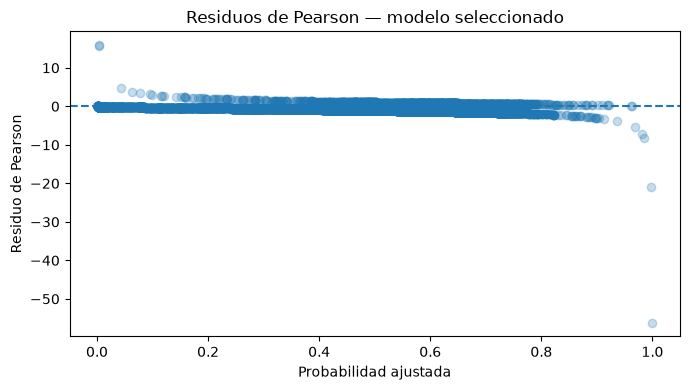

,resid_pearson,leverage,cooks_d,cooks_alerta,leverage_alerta
8071,-56.1651,0.0002,0.0927,True,False
5152,-21.0160,0.0005,0.0381,True,False
7600,15.7883,0.0008,0.0319,True,False
6700,15.8701,0.0008,0.0319,True,False
9238,-7.1441,0.0020,0.0173,True,True
8308,-8.1615,0.0010,0.0115,True,False
4623,2.1767,0.0124,0.0100,True,True
4564,2.1178,0.0129,0.0099,True,True
8106,4.6587,0.0027,0.0097,True,True
6684,-5.4953,0.0019,0.0097,True,True


In [23]:
infl = best_model.get_influence()
sf = infl.summary_frame()

diag = pd.DataFrame({
    "resid_pearson": best_model.resid_pearson,
    "leverage": sf["hat_diag"].values,
    "cooks_d": sf["cooks_d"].values
}, index=Xtr_all.index)

n = len(diag)
diag["cooks_alerta"] = diag["cooks_d"] > 4/n
diag["leverage_alerta"] = diag["leverage"] > 2*(len(BEST_VARS)+1)/n

display(diag.describe().T.round(4))
print("Cook > 4/n:", int(diag["cooks_alerta"].sum()))
print("Leverage alto:", int(diag["leverage_alerta"].sum()))

plt.figure(figsize=(7,4))
plt.scatter(best_model.fittedvalues, best_model.resid_pearson, alpha=.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Probabilidad ajustada")
plt.ylabel("Residuo de Pearson")
plt.title("Residuos de Pearson — modelo seleccionado")
plt.tight_layout()
plt.show()

display(diag.sort_values("cooks_d", ascending=False).head(10).round(4))

# PARTE V — Bootstrap del mejor modelo

## 23. Conservación de signo y estabilidad de coeficientes

Se remuestrea el conjunto de entrenamiento con reemplazo y se reajusta en cada réplica **la misma especificación ponderada**. Para cada coeficiente se reporta:

- **% de réplicas que conservan el signo** del coeficiente original (lo que pide el docente). Se considera estable si el signo se conserva en al menos 97,5 % de las réplicas, lo que equivale a que el IC percentil al 95 % no cruce 0.
- IC 95 % tradicional (Wald) e IC 95 % bootstrap percentil, para coeficientes y odds ratios.
- **Razón de anchos** IC bootstrap / IC tradicional: valores claramente mayores que 1 indican que el error estándar del modelo subestima la incertidumbre real.

In [24]:
rng = np.random.default_rng(RANDOM_STATE)
boot_coefs = []
fallos = 0
cols_b = ["const"] + BEST_VARS

for b in range(BOOTSTRAP_B):
    pos = rng.integers(0, len(Xtr_all), len(Xtr_all))
    try:
        mb = fit_logit(Xtr_all.iloc[pos], ytr.iloc[pos], BEST_VARS)
        boot_coefs.append(mb.params.reindex(cols_b).values)
    except Exception:
        fallos += 1

boot = pd.DataFrame(boot_coefs, columns=cols_b)
print("Bootstrap exitosos:", len(boot), "| fallos:", fallos)

trad_ci = best_model.conf_int().reindex(cols_b)
rows = []
for v in cols_b:
    coef = best_model.params[v]
    lo, hi = np.percentile(boot[v], [2.5, 97.5])
    rows.append({
        "Variable": v,
        "Coef": coef,
        "%_signo_conservado": 100 * np.mean(np.sign(boot[v]) == np.sign(coef)),
        "IC_trad_inf": trad_ci.loc[v, 0], "IC_trad_sup": trad_ci.loc[v, 1],
        "IC_boot_inf": lo, "IC_boot_sup": hi,
        "Razon_anchos": (hi - lo) / (trad_ci.loc[v, 1] - trad_ci.loc[v, 0]),
        "OR": np.exp(coef),
        "OR_trad_inf": np.exp(trad_ci.loc[v, 0]), "OR_trad_sup": np.exp(trad_ci.loc[v, 1]),
        "OR_boot_inf": np.exp(lo), "OR_boot_sup": np.exp(hi),
    })
tabla_boot = pd.DataFrame(rows)
tabla_boot["Estable"] = tabla_boot["%_signo_conservado"] >= 97.5
display(tabla_boot.round(3))

Bootstrap exitosos: 2000 | fallos: 0


,Variable,Coef,%_signo_conservado,IC_trad_inf,IC_trad_sup,IC_boot_inf,IC_boot_sup,Razon_anchos,OR,OR_trad_inf,OR_trad_sup,OR_boot_inf,OR_boot_sup,Estable
0,const,-0.206,99.0,-0.339,-0.074,-0.400,-0.038,1.372,0.813,0.713,0.928,0.670,0.963,True
1,Administrative,0.090,99.8,0.041,0.138,0.027,0.150,1.271,1.094,1.042,1.148,1.028,1.162,True
2,ProductRelated_Duration,0.243,100.0,0.185,0.301,0.160,0.328,1.448,1.275,1.203,1.352,1.174,1.388,True
3,ExitRates,-1.469,100.0,-1.603,-1.335,-1.733,-1.245,1.820,0.230,0.201,0.263,0.177,0.288,True
4,SpecialDay,-0.270,100.0,-0.335,-0.204,-0.386,-0.173,1.618,0.764,0.715,0.815,0.680,0.841,True
5,VisitorType_Returning_Visitor,-0.405,100.0,-0.530,-0.279,-0.561,-0.238,1.290,0.667,0.588,0.756,0.570,0.788,True


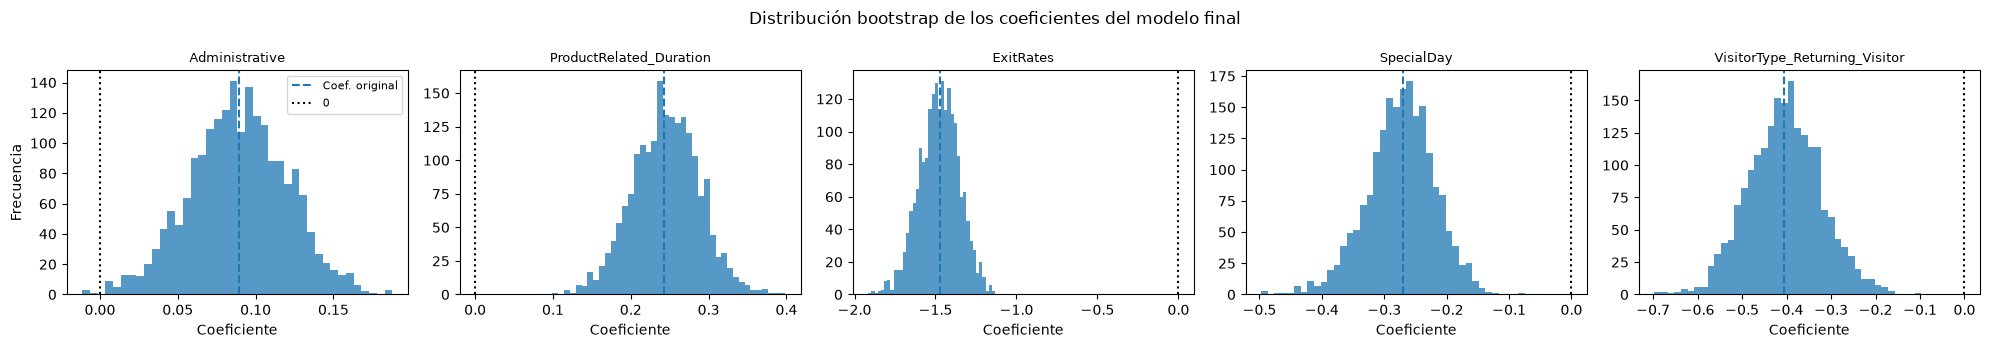

In [25]:
vars_plot = [x for x in cols_b if x != "const"]
fig, axes = plt.subplots(1, len(vars_plot), figsize=(4*len(vars_plot), 3.5), squeeze=False)
for ax, v in zip(axes[0], vars_plot):
    ax.hist(boot[v], bins=40, alpha=.75)
    ax.axvline(best_model.params[v], linestyle="--", label="Coef. original")
    ax.axvline(0, color="k", linestyle=":", label="0")
    ax.set_title(v, fontsize=9)
    ax.set_xlabel("Coeficiente")
axes[0][0].set_ylabel("Frecuencia")
axes[0][0].legend(fontsize=8)
plt.suptitle("Distribución bootstrap de los coeficientes del modelo final")
plt.tight_layout()
plt.show()

# PARTE VI — Impacto de la imputación sobre el modelo final

## 24. Mismo modelo final en las tres estrategias

Se reajusta exactamente la misma especificación (ponderada) bajo eliminación, mediana e imputación por regresión. Como la eliminación también reduce el conjunto de prueba, las métricas de cada estrategia sobre su propio test no son estrictamente comparables. Por eso se agrega un **test común**: las sesiones de prueba sin faltantes, cuyos valores son idénticos en las tres estrategias.

In [26]:
estrategias_modelo = {
    "Eliminación": (train_del, test_del),
    "Mediana": (train_med, test_med),
    "Regresión": (train_reg, test_reg)
}
idx_comun = test_del.index

comparacion_imp = []
coef_imp = []
for estrategia, (tr, te) in estrategias_modelo.items():
    Xtr_e, Xte_e, _ = preparar_matrices(tr, te)
    ytr_e = tr["Revenue"].astype(int)
    yte_e = te["Revenue"].astype(int)

    mod = fit_logit(Xtr_e, ytr_e, BEST_VARS)
    p = predecir(mod, Xte_e, BEST_VARS)
    pred = (p >= .5).astype(int)
    p_c = p.loc[idx_comun]
    y_c = yte_e.loc[idx_comun]

    comparacion_imp.append({
        "Estrategia": estrategia,
        "n_train": len(tr), "n_test": len(te),
        "Accuracy_test": accuracy_score(yte_e, pred),
        "Recall_test": recall_score(yte_e, pred, zero_division=0),
        "AUC_test": roc_auc_score(yte_e, p),
        "Recall_test_común": recall_score(y_c, (p_c >= .5).astype(int)),
        "AUC_test_común": roc_auc_score(y_c, p_c),
    })

    ci = mod.conf_int()
    for v in ["const"] + BEST_VARS:
        coef_imp.append({
            "Estrategia": estrategia, "Variable": v,
            "Coef": mod.params[v], "OR": np.exp(mod.params[v]),
            "IC95_OR_inf": np.exp(ci.loc[v, 0]), "IC95_OR_sup": np.exp(ci.loc[v, 1]),
            "p": mod.pvalues[v]
        })

tabla_impacto = pd.DataFrame(comparacion_imp)
tabla_coef_imp = pd.DataFrame(coef_imp)
print("Test común:", len(idx_comun), "sesiones")
display(tabla_impacto.round(4))
display(tabla_coef_imp.pivot(index="Variable", columns="Estrategia", values="OR").round(4))
display(tabla_coef_imp.round(4))

Test común: 2863 sesiones


,Estrategia,n_train,n_test,Accuracy_test,Recall_test,AUC_test,Recall_test_común,AUC_test_común
0,Eliminación,6695,2863,0.5934,0.7254,0.7011,0.7254,0.7011
1,Mediana,8631,3699,0.6031,0.7133,0.6984,0.7183,0.7021
2,Regresión,8631,3699,0.5980,0.7360,0.7076,0.7394,0.7023


Estrategia,Eliminación,Mediana,Regresión
Variable,,,
Administrative,1.0889,1.1173,1.0937
ExitRates,0.1769,0.2208,0.2301
ProductRelated_Duration,1.2633,1.2878,1.2753
SpecialDay,0.7571,0.7554,0.7636
VisitorType_Returning_Visitor,0.6898,0.6648,0.6670
const,0.6956,0.8103,0.8135


,Estrategia,Variable,Coef,OR,IC95_OR_inf,IC95_OR_sup,p
0,Eliminación,const,-0.3630,0.6956,0.5946,0.8138,0.0000
1,Eliminación,Administrative,0.0851,1.0889,1.0314,1.1496,0.0021
2,Eliminación,ProductRelated_Duration,0.2338,1.2633,1.1816,1.3508,0.0000
3,Eliminación,ExitRates,-1.7319,0.1769,0.1500,0.2087,0.0000
4,Eliminación,SpecialDay,-0.2783,0.7571,0.7010,0.8176,0.0000
5,Eliminación,VisitorType_Returning_Visitor,-0.3713,0.6898,0.5972,0.7968,0.0000
6,Mediana,const,-0.2103,0.8103,0.7101,0.9246,0.0018
7,Mediana,Administrative,0.1109,1.1173,1.0656,1.1716,0.0000
8,Mediana,ProductRelated_Duration,0.2530,1.2878,1.2166,1.3633,0.0000
9,Mediana,ExitRates,-1.5103,0.2208,0.1921,0.2540,0.0000


### Análisis de Impacto y Recomendación 
Al observar la tabla de impacto sobre el conjunto de prueba común (2.863 sesiones idénticas para los tres métodos), se constata que **la estrategia de imputación no cambia las conclusiones del modelo**. 

1. **Métricas de Desempeño:** La variación en la capacidad discriminativa es virtualmente nula. El AUC en el test común fluctúa marginalmente entre $0,7011$ (Eliminación) y $0,7023$ (Regresión).
2. **Estabilidad de Coeficientes:** Aunque estimadores como `ExitRates` presentan ligeros ajustes de magnitud (pasando de $-1,73$ en eliminación a $-1,47$ en regresión), todos los coeficientes mantienen intactos su signo (direccionalidad del efecto) y su significancia estadística ($p < 0,05$).

**Recomendación:** Se recomienda mantener la **Imputación por Regresión Múltiple**. A diferencia de la eliminación (que descarta 2.772 observaciones mermando la potencia estadística) y la mediana (que atenúa la correlación bivariada evidenciada en S1/S2, de 0,913 a 0,867), la regresión preserva la estructura multidimensional de los datos y entrega un modelo estable frente a la estrategia de tratamiento de faltantes.

# PARTE VII — `PageValues`: escenario condicionado a su disponibilidad

## 25. ¿Cuánto cambiaría el modelo si `PageValues` estuviera disponible?

`PageValues` queda **fuera del modelo recomendado**. Este análisis solo cuantifica cuánto ganaría el modelo si se confirmara que la variable está disponible en el momento de predecir; si se calcula con información posterior a la compra, la ganancia sería fuga de información (*target leakage*) y no capacidad predictiva real.

In [27]:
vars_con_page = BEST_VARS + ["PageValues"]
mod_con_page = fit_logit(Xtr_all, ytr, vars_con_page)

rows = []
for nombre, mod, vars_ in [("Recomendado (sin PageValues)", best_model, BEST_VARS),
                           ("Condicionado (+ PageValues)", mod_con_page, vars_con_page)]:
    r, cms = evaluar_modelo(mod, Xtr_all, ytr, Xte_all, yte, vars_, nombre)
    rows.append(r[1])
tabla_page = pd.DataFrame(rows).drop(columns="Split")
display(tabla_page.round(4))

,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Recomendado (sin PageValues),0.598,0.2396,0.736,0.3615,0.7076
1,Condicionado (+ PageValues),0.867,0.5554,0.701,0.6198,0.8747


# PARTE VIII — Escenario de decisión: campaña de 1.000 sesiones

La retroalimentación de S2 indicó que la simulación debía modelar el problema y no repetir el IC de S1. Aquí se simula el uso del modelo en una situación concreta: **una campaña que recibe 1.000 sesiones** y usa el modelo final para decidir a qué sesiones mostrar una intervención (por ejemplo, un cupón o un chat de ayuda).

1. **Línea base (azar):** compras ~ Binomial(1.000; 0,1547). Indica cuántas compras se esperan solo por variabilidad muestral.
2. **Con el modelo:** se extraen 1.000 sesiones de prueba con reemplazo, 10.000 veces, y se cuenta cuántas compras detecta el modelo, cuántas omite y cuántas falsas alarmas genera.

Línea base: compras por cada 1000 sesiones = 154.6 (95 %: 133–178)


,Media,P2.5,P97.5
Compras_reales,154.617,132.000,177.000
Sesiones_intervenidas,475.060,444.000,506.000
Compras_detectadas,113.898,94.000,134.000
Compras_omitidas,40.719,29.000,53.000
Falsas_alarmas,361.162,331.000,391.000
Precision,0.240,0.201,0.279


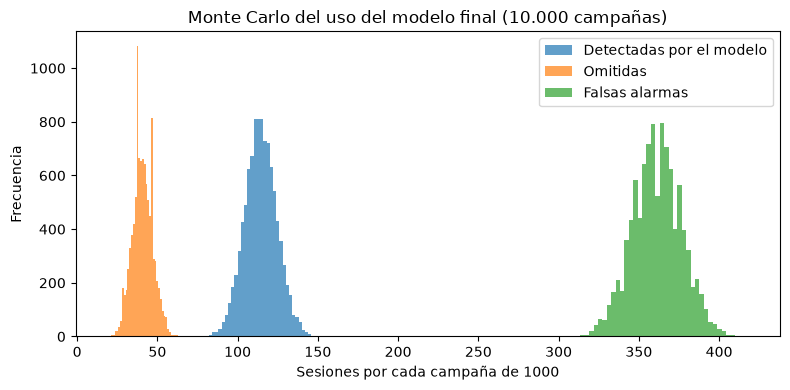

In [28]:
p_compra = df_original["Revenue"].mean()
rng_mc = np.random.default_rng(RANDOM_STATE)

compras_azar = rng_mc.binomial(MC_SESIONES, p_compra, size=MC_REPS)
lo_b, hi_b = np.percentile(compras_azar, [2.5, 97.5])
print(f"Línea base: compras por cada {MC_SESIONES} sesiones = {compras_azar.mean():.1f} "
      f"(95 %: {lo_b:.0f}–{hi_b:.0f})")

p_te = predecir(best_model, Xte_all, BEST_VARS).values
pred_te = (p_te >= .5).astype(int)
y_te = yte.values

sim = []
for _ in range(MC_REPS):
    i = rng_mc.integers(0, len(y_te), MC_SESIONES)
    y_s, pr_s = y_te[i], pred_te[i]
    tp = int(((y_s == 1) & (pr_s == 1)).sum())
    fp = int(((y_s == 0) & (pr_s == 1)).sum())
    fn = int(((y_s == 1) & (pr_s == 0)).sum())
    sim.append({"Compras_reales": tp + fn, "Sesiones_intervenidas": tp + fp,
                "Compras_detectadas": tp, "Compras_omitidas": fn, "Falsas_alarmas": fp,
                "Precision": tp / max(tp + fp, 1)})
sim = pd.DataFrame(sim)

resumen_mc = sim.describe(percentiles=[.025, .975]).T[["mean", "2.5%", "97.5%"]]
resumen_mc.columns = ["Media", "P2.5", "P97.5"]
display(resumen_mc.round(3))

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(sim["Compras_detectadas"], bins=40, alpha=.7, label="Detectadas por el modelo")
ax.hist(sim["Compras_omitidas"], bins=40, alpha=.7, label="Omitidas")
ax.hist(sim["Falsas_alarmas"], bins=40, alpha=.7, label="Falsas alarmas")
ax.set_xlabel(f"Sesiones por cada campaña de {MC_SESIONES}")
ax.set_ylabel("Frecuencia")
ax.set_title("Monte Carlo del uso del modelo final (10.000 campañas)")
ax.legend()
plt.tight_layout()
plt.show()

# PARTE IX — Síntesis automática de resultados

## Síntesis del modelo
La integración de las fases S1, S2 y S3 permite responder la pregunta de investigación: las métricas de navegación de la sesión se asocian de forma estable con la conversión y permiten discriminarla con capacidad moderada (AUC ≈ 0,71), aun excluyendo `PageValues` para evitar el riesgo de fuga de información (*target leakage*).

1. **Variables Críticas Identificadas:** El modelo final (Reducido por BIC) demuestra que métricas de fricción en la navegación (`ExitRates`), tiempo de interés en productos (`ProductRelated_Duration`) y lealtad del usuario (`VisitorType_Returning_Visitor`) son las variables más asociadas con la probabilidad de compra. La estabilidad empírica de estas variables fue corroborada mediante Bootstrap no paramétrico, donde conservaron su signo original en el 100% de las $2.000$ remuestras.
2. **Toma de Decisiones y Valor de Negocio:** La simulación Monte Carlo aterriza el desempeño estadístico a un caso de uso real. Al implementar ponderación de clases (`freq_weights`), el algoritmo sacrifica exactitud global pero optimiza el *Recall* (sobre un 73% en prueba). En una campaña de 1.000 sesiones, el sistema asume un volumen controlado de falsas alarmas como *trade-off* necesario para maximizar la detección de verdaderos compradores: interviene ≈ 475 sesiones y capta ≈ 114 compras, 1,55 veces más que una selección al azar. Esta lógica es conveniente cuando la intervención es de bajo costo (como un cupón o asistencia en línea); si fuera costosa, convendría subir el umbral. Aplicarla durante la sesión exigiría calcular estas métricas en tiempo real, algo que el dataset no permite verificar.
   
La siguiente celda imprime los principales resultados numéricos para facilitar la redacción del informe final. La interpretación debe mantener lenguaje de **asociación**, no causalidad.

In [29]:
print("=== RESUMEN S3 ===")
print("Estrategia principal de imputación:", METODO_PRINCIPAL)
print("Excluidas por VIF:", [e["Excluida"] for e in excluidas_vif])
print("PageValues: fuera de los modelos (escenario condicionado en Parte VII)")
print("Modelo seleccionado:", BEST_NAME, "| Variables:", BEST_VARS)

print("\nMétricas de prueba de los tres modelos ponderados:")
display(metricas_modelos.query("Split == 'Test'").round(4))
print("\nSelección por validación cruzada:")
display(cv_res.round(4))
print("\nEfecto de la ponderación:")
display(tabla_weight.round(4))
print("\nBootstrap:")
display(tabla_boot[["Variable", "Coef", "%_signo_conservado", "Razon_anchos", "OR", "OR_boot_inf", "OR_boot_sup", "Estable"]].round(3))
print("\nImpacto de imputación:")
display(tabla_impacto.round(4))
print("\nEscenario PageValues:")
display(tabla_page.round(4))
print("\nCampaña de 1.000 sesiones:")
display(resumen_mc.round(1))

=== RESUMEN S3 ===
Estrategia principal de imputación: Regresión
Excluidas por VIF: ['BounceRates']
PageValues: fuera de los modelos (escenario condicionado en Parte VII)
Modelo seleccionado: M3_Reducido_BIC | Variables: ['Administrative', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay', 'VisitorType_Returning_Visitor']

Métricas de prueba de los tres modelos ponderados:


,Modelo,Split,Accuracy,Precision,Recall,F1,AUC
1,M1_S1S2,Test,0.6007,0.2416,0.7395,0.3642,0.7087
3,M2_Stepwise_AIC,Test,0.5975,0.2393,0.7360,0.3612,0.7089
5,M3_Reducido_BIC,Test,0.5980,0.2396,0.7360,0.3615,0.7076



Selección por validación cruzada:


,AUC_cv,AUC_cv_de,Recall_cv,n_variables,Delta_AUC_mejor
Modelo,,,,,
M1_S1S2,0.7276,0.0047,0.7605,5,0.0044
M2_Stepwise_AIC,0.7319,0.0059,0.7672,7,0.0000
M3_Reducido_BIC,0.7320,0.0037,0.7657,5,0.0000



Efecto de la ponderación:


...

,Estrategia,n_train,n_test,Accuracy_test,Recall_test,AUC_test,Recall_test_común,AUC_test_común
0,Eliminación,6695,2863,0.5934,0.7254,0.7011,0.7254,0.7011
1,Mediana,8631,3699,0.6031,0.7133,0.6984,0.7183,0.7021
2,Regresión,8631,3699,0.5980,0.7360,0.7076,0.7394,0.7023



Escenario PageValues:


,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Recomendado (sin PageValues),0.598,0.2396,0.736,0.3615,0.7076
1,Condicionado (+ PageValues),0.867,0.5554,0.701,0.6198,0.8747



Campaña de 1.000 sesiones:


,Media,P2.5,P97.5
Compras_reales,154.6,132.0,177.0
Sesiones_intervenidas,475.1,444.0,506.0
Compras_detectadas,113.9,94.0,134.0
Compras_omitidas,40.7,29.0,53.0
Falsas_alarmas,361.2,331.0,391.0
Precision,0.2,0.2,0.3


# 26. Conclusiones integradas

El desarrollo de S3 mantiene la progresión **S1 → S2 → S3** e incorpora la retroalimentación de S2. S1 caracterizó el desbalance de `Revenue`, la asimetría de las variables y las asociaciones principales; S2 validó con remuestreo las correlaciones relevantes (entre ellas `BounceRates`–`ExitRates`, r ≈ 0,913) y mostró que los extremos no dependen de observaciones individuales. Sobre esa base se construyó el modelamiento final.

### Manejo de faltantes
La base original no tiene faltantes, por lo que se indujo de forma reproducible un **12 % MCAR** en `ProductRelated_Duration` y `ExitRates`, sin tocar `Revenue`. La imputación por regresión (sin usar `PageValues`) superó claramente a la mediana: el RMSE bajó de **1.860,9 a 832,4** en `ProductRelated_Duration` y de **0,0471 a 0,0195** en `ExitRates`, y preservó las correlaciones de S1 (r `BounceRates`–`ExitRates`: 0,922 vs 0,913 original; la mediana la atenúa a 0,867). Se adopta como estrategia principal.

### Filtro VIF previo y exclusión de `PageValues`
Antes de modelar, `ExitRates` (VIF 7,54) y `BounceRates` (VIF 6,83) superaron el umbral, con r = 0,919 entre ellas. Se conservó `ExitRates`, validada en S1/S2, y se excluyó `BounceRates`; tras el filtro todos los VIF quedaron bajo 4,5. `PageValues` se dejó fuera de los tres modelos hasta confirmar que está disponible al momento de predecir.

### Comparación de modelos (ponderados, peso 3,23 para compras)
Los tres modelos tienen desempeño muy similar en prueba (AUC entre **0,708 y 0,709**, recall ≈ **0,74**). La selección se hizo con validación cruzada de 5 particiones **dentro de entrenamiento**, sin usar el test: M2 (7 variables) y el modelo reducido M3 (5 variables) empatan en AUC_cv ≈ **0,732**, por lo que se eligió **M3 reducido** por parsimonia. Sus variables son `Administrative`, `ProductRelated_Duration`, `ExitRates`, `SpecialDay` y `VisitorType_Returning_Visitor`.

Interpretación (OR por cada desviación estándar, manteniendo lo demás constante; asociación, no causalidad):
- `ExitRates`: OR ≈ **0,23** — sesiones con mayor tasa de salida tienen chances de compra mucho menores.
- `ProductRelated_Duration`: OR ≈ **1,28** — más tiempo en páginas de producto se asocia a mayores chances de compra.
- `Administrative`: OR ≈ **1,09**.
- `SpecialDay`: OR ≈ **0,76** — la cercanía a fechas especiales se asocia a menor conversión en la misma sesión.
- Visitante recurrente: OR ≈ **0,67** frente a visitantes nuevos.

### Ponderación de clases
Sin ponderación el modelo es prácticamente inútil para detectar compras con umbral 0,5: recall **1,0 %** (6 de 572 compras de prueba). Con ponderación el recall sube a **73,6 %** (421 de 572) con el mismo AUC (0,705 → 0,708). El costo es una precision de **24 %**: el modelo prioriza no perder compradores a cambio de falsas alarmas.

### Diagnóstico y estabilidad (bootstrap, 2.000 réplicas, 0 fallos)
Los cinco coeficientes **conservan su signo en ≥ 99,8 % de las réplicas** y sus IC bootstrap de OR no incluyen 1: ninguna variable cambia de dirección. Sin embargo, los IC bootstrap son **entre 1,27 y 1,82 veces más anchos** que los tradicionales (máximo en `ExitRates`), lo que indica que los errores estándar del GLM ponderado subestiman la incertidumbre; para el informe deben reportarse los IC bootstrap. El VIF máximo del modelo final es 1,25. El Box-Tidwell sugiere no linealidad en el logit para `ProductRelated_Duration` (p < 0,001) y `ExitRates` (p ≈ 0,005); con n = 8.631 la prueba es muy sensible, pero se registra como limitación (una transformación logarítmica sería la extensión natural).

### Impacto de la imputación
El mismo modelo ajustado con las tres estrategias conserva signos y magnitudes similares; el cambio más visible es en `ExitRates` (OR 0,18 con eliminación vs 0,23 con regresión). En el **test común** de 2.863 sesiones sin faltantes, los AUC son prácticamente iguales (0,701–0,702), y la regresión logra el mayor recall (**73,9 %** vs 72,5 % eliminación y 71,8 % mediana). La eliminación descarta **1.936 sesiones de entrenamiento (22 %)** sin ganancia. **Recomendación:** imputación por regresión; las conclusiones sustantivas no dependen de la estrategia.

### `PageValues` como escenario condicionado
Si se confirmara que `PageValues` está disponible antes de la compra, el AUC subiría de **0,708 a 0,875** y la precision de 24 % a 56 % con recall similar (70 %). Esa diferencia muestra cuánto depende el desempeño de esta variable y por qué su disponibilidad debe verificarse antes de usarla: si se calcula con información posterior a la compra, la mejora sería fuga de información.

### Escenario de decisión: campaña de 1.000 sesiones
Solo por azar, una campaña de 1.000 sesiones tiene entre **133 y 178 compras** (media 155). Usando el modelo para decidir a quién intervenir, se interviene en ≈ **475 sesiones**, de las que ≈ **114 son compras** (95 %: 94–134) y ≈ 361 son falsas alarmas; se omiten ≈ 41 compras. Intervenir 475 sesiones al azar capturaría ≈ 73 compras, por lo que el modelo **concentra ~1,55 veces más compradores** en el grupo intervenido. Conviene usarlo cuando la intervención es barata (cupón, mensaje); si cada intervención fuese costosa, habría que subir el umbral.

### Respuesta a la pregunta de investigación
Sin usar `PageValues`, el análisis confirma que la tasa de salida, el tiempo en páginas de producto y administrativas, la cercanía a fechas especiales y el tipo de visitante se asocian de forma estable con la compra y permiten discriminarla con capacidad moderada (AUC ≈ 0,71). La ponderación de clases prioriza la detección de compradores potenciales a costa de falsas alarmas, un intercambio conveniente cuando la intervención comercial es de bajo costo. Los resultados **no permiten establecer causalidad**.

## Nota de reproducibilidad

Ejecutar **Restart Kernel → Run All** antes de entregar. Todas las decisiones (filtro VIF, selección del modelo, estabilidad bootstrap) siguen reglas explícitas en el código, de modo que los resultados se regeneran con la semilla 42.

# 27. Checklist de rúbrica y retroalimentación

### Imputación y faltantes
- [x] Referencia explícita a S1.
- [x] MCAR documentado y reproducible.
- [x] Regresión lineal múltiple con 4 predictores (sin `PageValues`).
- [x] Diagnóstico de regresiones de imputación.
- [x] Eliminación vs. mediana vs. regresión.
- [x] MAE/RMSE aprovechando valores verdaderos.
- [x] Tamaño, distribución y correlaciones comparados.

### Regresión logística
- [x] 70/30 estratificado por `Revenue`.
- [x] Decisión sobre outliers fundamentada en S1/S2.
- [x] **VIF antes de modelar**; `BounceRates` excluida (retroalimentación).
- [x] **`PageValues` fuera de los modelos** hasta confirmar disponibilidad (retroalimentación).
- [x] Estandarización y codificación.
- [x] Modelo 1 con variables validadas en S1/S2.
- [x] Modelo 2 stepwise AIC.
- [x] Modelo 3 reducido (BIC).
- [x] **Ponderación de clases (peso ≈ 3,2)** en los tres modelos (retroalimentación).
- [x] Coeficientes y OR.
- [x] Train/test: matriz de confusión, accuracy, precision, recall, F1 y AUC.
- [x] ROC comparativa.
- [x] Selección por validación cruzada en entrenamiento (sin usar test).

### Estabilidad y diagnóstico
- [x] Bootstrap de coeficientes del mejor modelo (2.000 réplicas).
- [x] **% de conservación de signo** por coeficiente (retroalimentación).
- [x] IC bootstrap de coeficientes y OR vs. IC tradicionales, con razón de anchos.
- [x] VIF del modelo final.
- [x] Linealidad en el logit.
- [x] Residuos e influencia.

### Impacto de imputación
- [x] Mismo modelo final en los tres datasets.
- [x] Tamaño muestral.
- [x] Coeficientes, OR e IC.
- [x] Accuracy, recall y AUC, incluido un test común comparable.
- [x] Recomendación basada en evidencia.

### Integración
- [x] Narrativa S1 → S2 → S3.
- [x] `PageValues` como escenario condicionado.
- [x] **Simulación del problema como escenario de decisión** (retroalimentación de Monte Carlo en S2).
- [x] Semilla y flujo reproducible.